# 06 · Query-based detector: RT-DETR

RT-DETR-L (Ultralytics, COCO-pretrained): a CNN backbone + hybrid transformer encoder, and a decoder whose **object queries**
each predict at most one object. Training matches predictions to ground truth one-to-one (Hungarian matching), so no NMS is needed.

**Same compute budget as the CNN detector:** each RT-DETR run gets the same wall-clock training time on the same T4 as the
YOLO11 reference of notebook 05, with the same frames, input size (1280) and evaluation.
Tuned parameter: the **number of queries** relative to scene density (300 vs 500; the densest train frame has 180 objects).

**Run:** Kaggle (GPU T4, Internet ON, inputs: competition + notebook 01 output; notebook 05 output for the learning-curve comparison)
or Google Colab (T4, Colab secret `KAGGLE_API_TOKEN`).

In [1]:
# environment: Kaggle (data attached as inputs) or Google Colab (data downloaded with the Kaggle API)
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
if IN_COLAB:
    # needs the Colab secret KAGGLE_API_TOKEN (Kaggle → Settings → API → Generate New Token)
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    drive.mount("/content/drive")                                   # outputs go to Google Drive, so they survive a disconnect
    INPUT, WORK = Path("/content/input"), Path("/content/drive/MyDrive/visdrone_hw2")
    subprocess.run("pip install -q -U kaggle pycocotools", shell=True, check=True)
    if not (INPUT / "comp" / "test_images.csv").exists():
        (INPUT / "comp").mkdir(parents=True, exist_ok=True)
        subprocess.run(f"kaggle competitions download -c {COMP} -p {INPUT / 'comp'} && cd {INPUT / 'comp'} "
                       "&& unzip -q -o '*.zip' && rm -f *.zip", shell=True, check=True)
else:
    INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
    subprocess.run("pip install -q pycocotools", shell=True)
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK)
print("Colab" if IN_COLAB else "Kaggle", "| outputs ->", WORK)

Kaggle | outputs -> /kaggle/working


In [2]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub


def build_yolo(root, out, step=4):
    """Same conversion as notebook 01: every `step`-th train frame, all val frames, ignored regions painted grey (114),
    boxes whose centre lies in an ignored region dropped. Used when notebook 01's output is not available (e.g. Colab)."""
    import shutil
    from PIL import Image
    out = Path(out)
    for split, st in [("train", step), ("val", 1)]:
        imgs, anns = load_split(root, split)
        (out / "images" / split).mkdir(parents=True, exist_ok=True); (out / "labels" / split).mkdir(parents=True, exist_ok=True)
        im = imgs.sort_values(["clip", "frame_id"]); im = im[im.groupby("clip").cumcount() % st == 0]
        by_img = dict(tuple(anns.groupby("image_id")))
        for r in im.itertuples():
            a = by_img.get(r.image_id, anns.iloc[:0])
            ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values; ob = a[a.iscrowd == 0]
            name = f"{r.clip}_{Path(r.file_name).stem}"; dst = out / "images" / split / f"{name}.jpg"
            if len(ig):
                px = np.array(Image.open(r.path).convert("RGB"))
                for x, y, w, h in ig.round().astype(int):
                    px[max(y, 0):y + h, max(x, 0):x + w] = 114
                Image.fromarray(px).save(dst, quality=95)
                cx, cy = (ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values
                inside = ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
                          (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)
                ob = ob[~inside]
            else:
                shutil.copy(r.path, dst)
            lines = [f"{c} {(x + w / 2) / r.width:.6f} {(y + h / 2) / r.height:.6f} {w / r.width:.6f} {h / r.height:.6f}"
                     for c, x, y, w, h in zip(ob.cls, ob.x, ob.y, ob.w, ob.h)]
            (out / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    (out / "data.yaml").write_text(f"path: {out}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
    return out

Writing vd_utils.py


In [3]:
subprocess.run("pip install -q ultralytics", shell=True, check=True)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, json, random, time
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from ultralytics import YOLO, RTDETR
import vd_utils as vd

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = vd.find_data_root(INPUT)
LOCAL = Path("/content/vd_yolo") if IN_COLAB else WORK / "vd_yolo"
hits = sorted(INPUT.glob("**/vd_yolo/data.yaml")) + sorted(LOCAL.parent.glob("vd_yolo/data.yaml"))
YOLO_DIR = hits[0].parent if hits else vd.build_yolo(ROOT, LOCAL, step=4)
DATA_YAML = WORK / "data.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(vd.CLASSES))}\n")
val_imgs, _ = vd.load_split(ROOT, "val")
VAL_GT = ROOT / "val" / "annotations_coco.json"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

def find_file(rel):
    hits = sorted(WORK.glob(rel)) + sorted(INPUT.glob(f"**/{rel}"))
    return hits[0] if hits else None
print("yolo dataset:", YOLO_DIR)

yolo dataset: /kaggle/input/notebooks/yarema1234/notebook0f34d49e70/vd_yolo


In [4]:
def predict(model, paths, imgsz, conf=0.001, bs=4):
    # {path: array N x 6 [cls, score, x, y, w, h]} in original pixels; small explicit chunks avoid GPU OOM
    out, t0 = {}, time.time()
    for k in range(0, len(paths), bs):
        for r in model.predict(paths[k:k + bs], imgsz=imgsz, conf=conf, max_det=500, verbose=False):
            b = r.boxes; xyxy = b.xyxy.cpu().numpy()
            out[r.path] = np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]]
    return out, (time.time() - t0) / len(paths) * 1000

def to_coco(preds, imgs):
    pid = dict(zip(imgs["path"], imgs["image_id"]))
    return [{"image_id": int(pid[p]), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for p, d in preds.items() for c, s, x, y, w, h in d]

## 1. Bipartite matching instead of NMS
For each training image, the Hungarian algorithm finds the one-to-one assignment between the N queries and the M ground-truth
objects that minimises a cost = classification cost + L1 box distance + GIoU cost. Every object gets exactly one query; all
other queries are trained to predict "no object". At inference a query that duplicates an object already claimed by another query
has learned to score low, so the output needs no NMS.

Effect on training: the matching of a query can change from one step to the next while predictions are still poor, which makes
the early training signal unstable and convergence slower than for dense CNN heads. RT-DETR shortens this with query selection
(queries are initialised from the top-scoring encoder features) and **denoising** training (noisy copies of the ground-truth boxes
are fed as extra queries with a fixed assignment). In dense scenes, the number of queries caps the number of detections per frame.

In [5]:
# RT-DETR-L configuration with a configurable number of queries (no weight depends on it, so COCO weights still load)
import ultralytics
base_yaml = (Path(ultralytics.__file__).parent / "cfg/models/rt-detr/rtdetr-l.yaml").read_text()
def rtdetr_yaml(nq):
    p = WORK / f"rtdetr-l-q{nq}.yaml"
    p.write_text(base_yaml.replace("RTDETRDecoder, [nc]]", f"RTDETRDecoder, [nc, 256, {nq}]]"))
    return str(p)

## 2. Experiments under a fixed time budget
| name | queries | why |
|---|---|---|
| `rtdetr_q300` | 300 (default) | reference |
| `rtdetr_q500` | 500 | up to 180 objects per frame plus many hard negatives; more queries give the matching more candidates per object |

Both: RT-DETR-L, 1280 px, batch 4 (gradients accumulated to 64 like YOLO), Ultralytics default optimiser and augmentation,
training stopped by the `time` budget below (cosine schedule fitted to that budget), seed 42.

In [6]:
TIME_H = 1.0                 # training hours per run; same order as the YOLO11s reference of notebook 05 (6 epochs ≈ 40-45 min + validation)
BASE = dict(imgsz=1280, epochs=100, time=TIME_H, batch=4, cos_lr=True, seed=SEED, workers=4 if not IN_COLAB else 2,
            device=DEVICE, project=str(WORK / "detr_runs"), exist_ok=True, plots=True)
EXPS = {"rtdetr_q300": 300, "rtdetr_q500": 500}

RESULTS, CURVES = {}, {}
for name, nq in EXPS.items():
    best = find_file(f"detr_runs/{name}/weights/best.pt")
    if best is None:
        t0 = time.time()
        model = RTDETR(rtdetr_yaml(nq)).load("rtdetr-l.pt")                  # COCO-pretrained weights
        model.train(data=str(DATA_YAML), name=name, **BASE)
        train_min = (time.time() - t0) / 60
        best = WORK / "detr_runs" / name / "weights" / "best.pt"
        del model; gc.collect(); torch.cuda.empty_cache()
    else:
        print("reusing", best); train_min = np.nan
    rc = best.parent.parent / "results.csv"
    if rc.exists(): CURVES[name] = pd.read_csv(rc)
    model = RTDETR(best)
    preds, ms = predict(model, val_imgs["path"].tolist(), imgsz=1280)
    RESULTS[name] = {**vd.coco_eval(VAL_GT, to_coco(preds, val_imgs)), "ms / image (incl. disk)": ms, "train min": train_min}
    del model; gc.collect(); torch.cuda.empty_cache()
    pd.DataFrame(RESULTS).T.to_csv(WORK / "results_detr.csv")

R = pd.DataFrame(RESULTS).T
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms / image (incl. disk)", "train min"]
display(R[MAIN].astype(float).round(4))
display(R[[f"AP_{c}" for c in vd.CLASSES]].T.astype(float).round(3))

Using 6072 train, 2846 val images for fraction=1.0 at imgsz=1280
                   all       2846     112903      0.621      0.514      0.517      0.268
                   all       2846     112903      0.611      0.514      0.522      0.264
                   all       2846     112903      0.695      0.532      0.557       0.29
3 epochs completed in 1.058 hours.
                   all       2846     112903      0.695      0.532      0.557      0.289
                person       2776      49486      0.727      0.711      0.721      0.312
               bicycle        982       6020      0.673      0.563      0.588      0.255
                   car       2382      31740       0.75      0.739      0.717      0.456
                   van       2266       6791       0.66      0.411      0.518      0.301
                 truck        985       1359      0.549       0.58      0.589      0.314
              tricycle       1662       5257      0.706      0.453      0.567       0.26
... (4 lin

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms / image (incl. disk),train min
rtdetr_q300,0.2904,0.5540,0.2647,0.1584,0.2517,0.4584,263.7565,75.870
rtdetr_q500,0.2746,0.5269,0.2493,0.1361,0.2448,0.4567,248.9289,68.004


,rtdetr_q300,rtdetr_q500
AP_person,0.309,0.309
AP_bicycle,0.256,0.299
AP_car,0.457,0.450
AP_van,0.304,0.257
AP_truck,0.316,0.220
AP_tricycle,0.267,0.250
AP_bus,0.278,0.273
AP_motor,0.140,0.143


## 3. Validation mAP over training time: RT-DETR vs the CNN detector
Per-epoch validation mAP (Ultralytics' own validation on the masked val frames) against cumulative training time.
The YOLO11 curve comes from notebook 05 (attach its output).

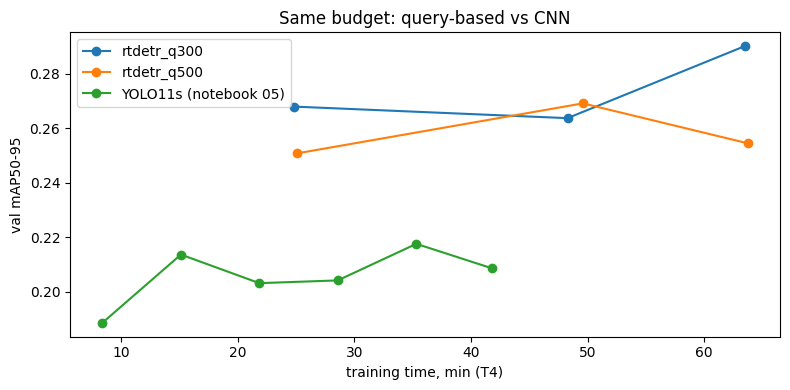

rtdetr_q300: 3 epochs in the budget, last-epoch mAP 0.290, still rising: True
rtdetr_q500: 3 epochs in the budget, last-epoch mAP 0.254, still rising: False


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
yolo_rc = find_file("yolo_runs/yolo_s1280_e6/results.csv")
curves = dict(CURVES) | ({"YOLO11s (notebook 05)": pd.read_csv(yolo_rc)} if yolo_rc else {})
for name, c in curves.items():
    c.columns = c.columns.str.strip()
    ax.plot(c["time"] / 60, c["metrics/mAP50-95(B)"], marker="o", label=name)
ax.set_xlabel("training time, min (T4)"); ax.set_ylabel("val mAP50-95"); ax.legend(); ax.set_title("Same budget: query-based vs CNN")
plt.tight_layout(); plt.savefig(WORK / "curves_detr_vs_yolo.png", dpi=120); plt.show()
for name, c in CURVES.items():
    print(f"{name}: {len(c)} epochs in the budget, last-epoch mAP {c['metrics/mAP50-95(B)'].iloc[-1]:.3f}, "
          f"still rising: {c['metrics/mAP50-95(B)'].iloc[-1] >= c['metrics/mAP50-95(B)'].max() - 1e-4}")

## 4. Comparison with the other detector families
Uses the result tables of notebooks 03–05 if their outputs are attached.

In [8]:
rows = [R]
for f, tag in [("results_03.csv", "two-stage"), ("results_retina.csv", "one-stage anchor-based"), ("results_yolo.csv", "anchor-free")]:
    p = find_file(f)
    if p is not None:
        T = pd.read_csv(p, index_col=0); b = T["mAP"].astype(float).idxmax()
        rows.append(T.loc[[b]].rename(index={b: f"{b} ({tag})"}))
display(pd.concat(rows)[["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]].astype(float).round(4).sort_values("mAP", ascending=False))

,mAP,AP50,AP_small,AP_medium,AP_large
rtdetr_q300,0.2904,0.5540,0.1584,0.2517,0.4584
rtdetr_q500,0.2746,0.5269,0.1361,0.2448,0.4567
frcnn_base (two-stage),0.2245,0.4584,0.1046,0.2057,0.4166
yolo_s1536_e6 (anchor-free),0.2173,0.4233,0.1139,0.2073,0.3443


## 5. Test submission with the best RT-DETR run

In [9]:
BEST = R["mAP"].astype(float).idxmax(); print("best:", BEST)
model = RTDETR(find_file(f"detr_runs/{BEST}/weights/best.pt"))
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
tp, _ = predict(model, test["path"].tolist(), imgsz=1280)
dets = {i: tp.get(p, np.zeros((0, 6))) for i, p in zip(test["image_id"], test["path"])}
vd.write_submission(dets, ROOT / "test_images.csv", WORK / "submission_detr.csv")
print("written submission_detr.csv")

best: rtdetr_q300
written submission_detr.csv
